# Notebook 8 — Does region A fire less than region B?

**Summer course: data-analysis pitfalls**

One 30 minute recording, 150 well-isolated units. Ten of them were localized to
**region A**, a small target structure, and the other 140 to **region B**, the
surrounding tissue. That imbalance is not a mistake: it is what you get when one
of your two regions is thin, or when only a handful of cells are opto-tagged.

For each unit we have its total spike count, so its mean firing rate over the
session. We want to know whether the two regions fire at different rates. Welch's
t-test is the usual default for two groups with possibly different variances.

> ### The claim
> *"Units in region A fire at roughly half the rate of units in region B
> (5.1 vs 9.6 spikes/s, a 47% reduction; Welch's t-test, t = -2.7, p = 0.009)."*

Run it and you'll get it.

**The claim is false. Every one of the 150 units had its firing rate drawn from
the same distribution, and region was assigned with no reference to rate at all.**
Your job is to work out how a p-value of 0.009 appeared anyway.

`hints.md` has guiding questions and `notebook8_solution.ipynb` has the answer.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

C_A, C_B = 'tab:orange', 'tab:blue'


In [2]:
d = np.load('data/data.npz')
spike_counts = d['spike_counts']            # (units,) spikes in the session
duration     = float(d['duration'])         # s
region       = d['region']                  # (units,) 0 = region A, 1 = region B

rate = spike_counts / duration              # spikes/s, one number per unit
A, B = rate[region == 0], rate[region == 1]
print(f'{rate.size} units: {A.size} in region A, {B.size} in region B')
print(f'{duration/60:.0f} min recording')
print(f'region A: mean {A.mean():.2f} spikes/s')
print(f'region B: mean {B.mean():.2f} spikes/s')


150 units: 10 in region A, 140 in region B
30 min recording
region A: mean 5.10 spikes/s
region B: mean 9.57 spikes/s


## Step 1 — The figure and the test

On the left, the summary everyone plots: group means with SEM error bars. On the
right, the same numbers with every unit shown.


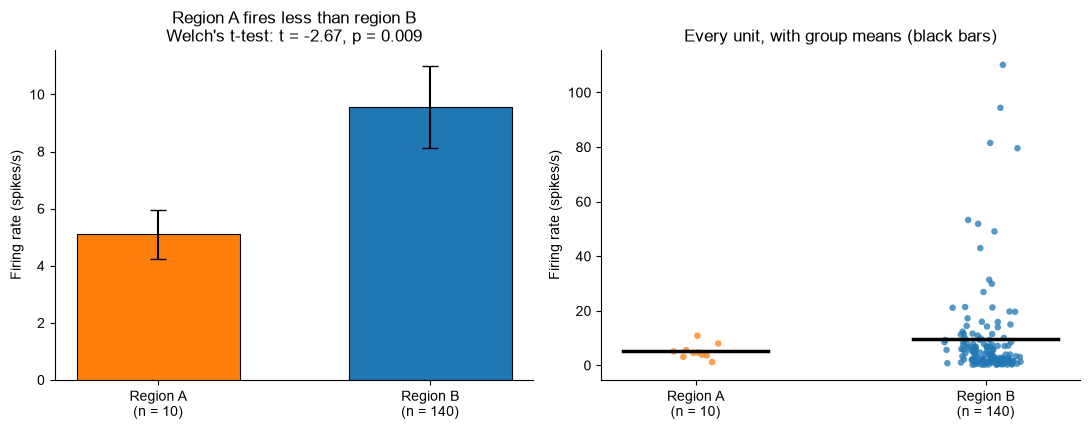

region A: mean   5.10, SD   2.70, n = 10
region B: mean   9.57, SD  17.07, n = 140
ratio of means A/B          : 0.533 (-47%)
Welch's t-test              : t = -2.668, p = 0.0091


In [3]:
means = [A.mean(), B.mean()]
sems  = [A.std(ddof=1)/np.sqrt(A.size), B.std(ddof=1)/np.sqrt(B.size)]

t_w, p_w = stats.ttest_ind(A, B, equal_var=False)      # Welch's t-test

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

axes[0].bar([0, 1], means, yerr=sems, capsize=6, width=0.6,
            color=[C_A, C_B], edgecolor='k', lw=0.8)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f'Region A\n(n = {A.size})', f'Region B\n(n = {B.size})'])
axes[0].set_ylabel('Firing rate (spikes/s)')
axes[0].set_title(f'Region A fires less than region B\n'
                  f"Welch's t-test: t = {t_w:.2f}, p = {p_w:.3f}")

rng = np.random.default_rng(0)
for i, (g, c) in enumerate(zip((A, B), (C_A, C_B))):
    axes[1].scatter(i + rng.normal(0, 0.06, g.size), g, s=22, color=c,
                    alpha=0.75, edgecolors='none')
    axes[1].plot([i - 0.25, i + 0.25], [g.mean()] * 2, color='k', lw=2.5)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels([f'Region A\n(n = {A.size})', f'Region B\n(n = {B.size})'])
axes[1].set_ylabel('Firing rate (spikes/s)')
axes[1].set_title('Every unit, with group means (black bars)')
plt.tight_layout(); plt.show()

print(f'region A: mean {A.mean():6.2f}, SD {A.std(ddof=1):6.2f}, n = {A.size}')
print(f'region B: mean {B.mean():6.2f}, SD {B.std(ddof=1):6.2f}, n = {B.size}')
print(f'ratio of means A/B          : {A.mean()/B.mean():.3f} '
      f'({(A.mean()/B.mean()-1)*100:+.0f}%)')
print(f"Welch's t-test              : t = {t_w:.3f}, p = {p_w:.4f}")


Region A fires at about half the rate of region B, p = 0.009.

Every unit in this dataset, in both regions, had its rate drawn from one and the
same distribution. **Where did this come from?**
